# Laying Hen Stress Vocalization Prep

Prepare a compact OpenFARM poultry audio dataset from the Zenodo laying-hen vocalization record.

This notebook is intentionally lean: verify source files, parse the MFCC/file metadata, optionally extract full audio to opaque filenames, build leakage-aware splits, run one shallow baseline, and package the Hugging Face dataset.

Source: https://zenodo.org/records/10433023


In [1]:
#@title Setup dependencies and imports
!pip -q install datasets huggingface_hub openpyxl scikit-learn soundfile mutagen

import hashlib
import json
import os
import random
import re
import shutil
import wave
import zipfile

import soundfile as sf
from mutagen import File as MutagenFile
from scipy.signal import resample_poly
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from datasets import Audio, Dataset, DatasetDict
from huggingface_hub import HfApi, login
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_columns", 160)
pd.set_option("display.max_colwidth", 180)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.4/194.4 kB 6.2 MB/s eta 0:00:00


In [2]:
#@title Configuration
RECORD_ID = "10433023"
ZENODO_API_URL = f"https://zenodo.org/api/records/{RECORD_ID}"
ZENODO_RECORD_URL = f"https://zenodo.org/records/{RECORD_ID}"

ANALYSIS_ZIP = "Laying Hens Vocalization Data Analysis Dec 26 2023.zip"
CONTROL_ZIP = "Laying Hens Vocalization Control Experiments Data.zip"
TREATMENT_ZIP = "Laying Hens Vocalization Treatment Experiments Data.zip"
EXPECTED_MD5 = {
    ANALYSIS_ZIP: "3e53c8a28eba3510705f5389608771c1",
    CONTROL_ZIP: "e5cb4fb7fd21ee6afe9bbcf725476e99",
    TREATMENT_ZIP: "3ea021e99b16e25ed0240cd7688386d5",
}

WORK_DIR = Path(os.environ.get(
    "OPENFARM_HEN_STRESS_WORK_DIR",
    "/content/openfarm_laying_hen_stress" if Path("/content").exists() else "laying_hen_stress_work",
))
RAW_DIR = WORK_DIR / "raw"
OUT_DIR = WORK_DIR / "prepared"
AUDIO_DIR = OUT_DIR / "audio"
for d in [RAW_DIR, OUT_DIR, AUDIO_DIR]:
    d.mkdir(parents=True, exist_ok=True)

HF_REPO_ID = "oliveirabruno01/openfarm-laying-hen-stress"  #@param {type:"string"}
PUSH_TO_HUB = True  #@param {type:"boolean"}
PRIVATE_REPO = False  #@param {type:"boolean"}

# Keep False on local machines. Flip to True in Colab before publishing the audio dataset.
DOWNLOAD_AUDIO_ARCHIVES = True  #@param {type:"boolean"}
REQUIRE_AUDIO_FOR_PUSH = True  #@param {type:"boolean"}

# Public HF audio is intentionally budgeted for small multimodal models. Gemma
# E2B/E4B audio supports up to 30s, but this benchmark uses 15s to stay fast and
# consistent with the openfarm_bioacustics environment default.
AUDIO_EXCERPT_MAX_SECONDS = 15.0  #@param {type:"number"}
AUDIO_EXCERPT_STRATEGY = "even_windows"  #@param ["even_windows", "center", "start"]
AUDIO_EXCERPT_WINDOW_COUNT = 5  #@param {type:"integer"}
AUDIO_EXCERPT_SAMPLE_RATE = 16000  #@param {type:"integer"}
AUDIO_EXCERPT_FORMAT = "WAV"
AUDIO_EXCERPT_SUBTYPE = "PCM_16"

# We hold out experimental day groups, not individual MFCC segments.
TEST_SIZE_FALLBACK = 0.25  #@param {type:"number"}
SPLIT_SEED_SEARCH = 1000  #@param {type:"integer"}

STRESS_CONTEXT_CHOICES = [
    "poststress_control",
    "prestress_control",
    "poststress_treatment",
    "prestress_treatment",
]

print("work dir:", WORK_DIR)
print("outputs:", OUT_DIR)
print("audio excerpt:", {
    "max_seconds": AUDIO_EXCERPT_MAX_SECONDS,
    "strategy": AUDIO_EXCERPT_STRATEGY,
    "window_count": AUDIO_EXCERPT_WINDOW_COUNT,
    "sample_rate_hz": AUDIO_EXCERPT_SAMPLE_RATE,
    "format": AUDIO_EXCERPT_FORMAT,
})


work dir: /content/openfarm_laying_hen_stress
outputs: /content/openfarm_laying_hen_stress/prepared
audio excerpt: {'max_seconds': 15.0, 'strategy': 'even_windows', 'window_count': 5, 'sample_rate_hz': 16000, 'format': 'WAV'}


In [3]:
#@title Download and verify Zenodo metadata / lightweight analysis archive

def md5_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    h = hashlib.md5()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


def download_file(url: str, path: Path, expected_md5: str | None = None) -> Path:
    if path.exists() and expected_md5 and md5_file(path) == expected_md5:
        print("already verified:", path.name)
        return path
    print("downloading:", path.name)
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        tmp = path.with_suffix(path.suffix + ".part")
        with tmp.open("wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
        tmp.replace(path)
    if expected_md5:
        got = md5_file(path)
        assert got == expected_md5, (path.name, got, expected_md5)
    print("verified:", path.name, path.stat().st_size, expected_md5 or md5_file(path))
    return path

record = requests.get(ZENODO_API_URL, timeout=60).json()
(RAW_DIR / "record.json").write_text(json.dumps(record, indent=2), encoding="utf-8")

print(record["metadata"]["title"])
print("doi:", record["metadata"].get("doi"))
print("license:", record["metadata"].get("license"))

files_by_key = {f["key"]: f for f in record["files"]}
for key, f in files_by_key.items():
    print(key, f["size"], f.get("checksum"))

analysis_path = download_file(files_by_key[ANALYSIS_ZIP]["links"]["self"], RAW_DIR / ANALYSIS_ZIP, EXPECTED_MD5[ANALYSIS_ZIP])

if DOWNLOAD_AUDIO_ARCHIVES:
    for key in [CONTROL_ZIP, TREATMENT_ZIP]:
        download_file(files_by_key[key]["links"]["self"], RAW_DIR / key, EXPECTED_MD5[key])
else:
    print("audio archive download skipped. Set DOWNLOAD_AUDIO_ARCHIVES=True in Colab before public audio push.")


Vocalization Patterns in Laying Hens - An Analysis of Stress-Induced Audio Responses
doi: 10.5281/zenodo.10433023
license: {'id': 'cc-by-4.0'}
Laying Hens Vocalization Control Experiments Data.zip 482016017 md5:e5cb4fb7fd21ee6afe9bbcf725476e99
Laying Hens Vocalization Treatment Experiments Data.zip 1999549757 md5:3ea021e99b16e25ed0240cd7688386d5
Laying Hens Vocalization Data Analysis Dec 26 2023.zip 12690105 md5:3e53c8a28eba3510705f5389608771c1
downloading: Laying Hens Vocalization Data Analysis Dec 26 2023.zip
verified: Laying Hens Vocalization Data Analysis Dec 26 2023.zip 12690105 3e53c8a28eba3510705f5389608771c1
downloading: Laying Hens Vocalization Control Experiments Data.zip
verified: Laying Hens Vocalization Control Experiments Data.zip 482016017 e5cb4fb7fd21ee6afe9bbcf725476e99
downloading: Laying Hens Vocalization Treatment Experiments Data.zip
verified: Laying Hens Vocalization Treatment Experiments Data.zip 1999549757 3ea021e99b16e25ed0240cd7688386d5


In [4]:
#@title Extract analysis artifacts and inspect source summary
analysis_dir = RAW_DIR / "analysis"
if analysis_dir.exists():
    shutil.rmtree(analysis_dir)
analysis_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(analysis_path) as zf:
    zf.extractall(analysis_dir)

ANALYSIS_ROOT = analysis_dir / "Laying Hens Vocalization Data Analysis"
print("analysis root:", ANALYSIS_ROOT)
for p in sorted(ANALYSIS_ROOT.iterdir()):
    kind = "dir" if p.is_dir() else f"{p.stat().st_size:,} bytes"
    print("-", p.name, kind)

mfcc_csv = ANALYSIS_ROOT / "Supplementary File S1 MFCC 40 Features.csv"
results_xlsx = ANALYSIS_ROOT / "Classification Results File.xlsx"
print("classification sheet:")
display(pd.read_excel(results_xlsx, header=None))


analysis root: /content/openfarm_laying_hen_stress/raw/analysis/Laying Hens Vocalization Data Analysis
- Classification Results File.xlsx 10,946 bytes
- Figure 1 Heatmap of MFCC Features.png 273,043 bytes
- Figure 2 Boxplot of MFCC Features.png 172,756 bytes
- Figure 3 Mfcc_features_specific_scatterplots.png 571,288 bytes
- Figure 4 Model Accuracy Epoch.jpg 80,190 bytes
- Figure 5 Mel Spectrogram.jpg 290,195 bytes
- Laying Hens Vocalization Classification_model dir
- Laying Hens Vocalization_classification Algorithm.html 900,960 bytes
- Laying Hens Vocalization_classification.ipynb 271,103 bytes
- Laying Hens Vocalization_classification.py 12,107 bytes
- Laying Hens Vocalization_trainer.py 7,186 bytes
- Laying Hens_front_end.py 11,432 bytes
- Laying Hens_recognizer.py 6,280 bytes
- Laying Hens_trainer.py 9,929 bytes
- Sample Audio File Ctrl_W5_D1_PoS_4.mp3 9,508,153 bytes
- Supplementary File S1 MFCC 40 Features.csv 393,533 bytes
classification sheet:


,0,1,2,3,4
0,NaN,NaN,NaN,NaN,NaN
1,NaN,Class,Treatment Label,Directory,Classification id
2,NaN,Control_4,NaN,PoststressControl,0
3,NaN,Control_5,NaN,PrestressControl,1
4,NaN,Treat_Post,Treatment 1,PoststressTreatment,2
5,NaN,Treat_Pre,Treatment 1,PrestressTreatment,3
6,NaN,NaN,NaN,NaN,NaN
7,NaN,Epoch 1000/1000\n75/75 [==============================] - 0s 4ms/step - loss: 0.5403 - accuracy: 0.7542 - val_loss: 0.7720 - val_accuracy: 0.6923\n loss: 0.5403 - loss in trai...,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN
9,NaN,Statistics\n________________________________________________________________\n precision recall f1-score support\n\n 0 0.85 0.80 0....,NaN,NaN,NaN


In [5]:
#@title Parse MFCC table and source filename semantics

def norm(value) -> str:
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value)).strip()


def opaque_id(text: str, prefix: str = "hen") -> str:
    digest = hashlib.sha256(("openfarm-laying-hen-stress-v1::" + text).encode("utf-8")).hexdigest()[:12]
    return f"{prefix}_{digest}"

raw_mfcc_df = pd.read_csv(mfcc_csv)
name_col = raw_mfcc_df.columns[0]
mfcc_cols = [c for c in raw_mfcc_df.columns if c.startswith("MFCC ")]

segment_df = raw_mfcc_df[raw_mfcc_df[name_col].astype(str).str.endswith(".wav", na=False)].copy()
segment_df = segment_df.rename(columns={name_col: "source_audio_filename"})
segment_df["source_audio_filename"] = segment_df["source_audio_filename"].map(norm)
for col in mfcc_cols:
    segment_df[col] = pd.to_numeric(segment_df[col], errors="coerce")
segment_df = segment_df.dropna(subset=mfcc_cols, how="any").reset_index(drop=True)
segment_df["mfcc_segment_index"] = segment_df.groupby("source_audio_filename").cumcount()

FILENAME_RE = re.compile(
    r"^(?P<arm>Ctrl|Trt1|Trt2)_W(?P<week>\d+)_D(?P<day>\d+)_(?P<phase>PoS|PrS)(?:_(?P<clip>\d+))?\.wav$",
    re.IGNORECASE,
)
ARM_MAP = {
    "Ctrl": ("control", "none"),
    "Trt1": ("treatment_1", "sudden_umbrella_opening"),
    "Trt2": ("treatment_2", "simulated_dog_barking"),
}
PHASE_MAP = {"PrS": "prestress", "PoS": "poststress"}

parsed_rows = []
for source_name in sorted(segment_df["source_audio_filename"].unique()):
    match = FILENAME_RE.match(source_name)
    assert match, source_name
    parts = match.groupdict()
    arm_raw = parts["arm"]
    phase_raw = parts["phase"]
    experiment_group, stressor = ARM_MAP[arm_raw]
    phase = PHASE_MAP[phase_raw]
    treatment_class = "control" if experiment_group == "control" else "treatment"
    stress_context = f"{phase}_{treatment_class}"
    stress_binary = "stress_response" if stress_context == "poststress_treatment" else "not_stress_response"
    parsed_rows.append({
        "source_audio_filename": source_name,
        "source_audio_id": opaque_id(source_name),
        "species": "laying_hen",
        "arm_code": arm_raw,
        "experiment_group": experiment_group,
        "stressor": stressor,
        "week": int(parts["week"]),
        "day": int(parts["day"]),
        "phase": phase,
        "clip_index": int(parts["clip"] or 1),
        "experimental_day_group": f"{arm_raw}_W{parts['week']}_D{parts['day']}",
        "stress_context": stress_context,
        "stress_binary": stress_binary,
    })

file_meta_df = pd.DataFrame(parsed_rows)
mfcc_agg = segment_df.groupby("source_audio_filename")[mfcc_cols].agg(["mean", "std"]).reset_index()
mfcc_agg.columns = ["source_audio_filename"] + [f"{col.lower().replace(' ', '_')}_{stat}" for col, stat in mfcc_agg.columns[1:]]
segment_counts = segment_df.groupby("source_audio_filename").size().rename("mfcc_segment_count").reset_index()

metadata_df = file_meta_df.merge(segment_counts, on="source_audio_filename").merge(mfcc_agg, on="source_audio_filename")
metadata_df["source_group_id"] = metadata_df["experimental_day_group"].map(lambda value: opaque_id(value, prefix="hen_group"))
metadata_df["audio_filename"] = metadata_df["source_audio_id"] + ".wav"
metadata_df["audio_available"] = False
metadata_df["audio"] = ""
metadata_df["audio_sha256"] = ""
metadata_df["source_audio_sha256"] = ""
metadata_df["duration_sec"] = np.nan
metadata_df["sample_rate_hz"] = np.nan
metadata_df["channels"] = np.nan
metadata_df["source_duration_sec"] = np.nan
metadata_df["source_sample_rate_hz"] = np.nan
metadata_df["source_channels"] = np.nan
metadata_df["excerpt_duration_sec"] = np.nan
metadata_df["excerpt_max_seconds"] = AUDIO_EXCERPT_MAX_SECONDS
metadata_df["excerpt_strategy"] = AUDIO_EXCERPT_STRATEGY
metadata_df["excerpt_window_count"] = AUDIO_EXCERPT_WINDOW_COUNT
metadata_df["excerpt_sample_rate_hz"] = AUDIO_EXCERPT_SAMPLE_RATE
metadata_df["excerpt_windows_sec"] = "[]"
metadata_df["audio_metadata_ok"] = False
metadata_df["audio_metadata_backend"] = "none"
metadata_df["audio_metadata_error"] = ""
metadata_df["source_archive"] = ""
metadata_df["source_archive_member"] = ""

print("MFCC segment rows:", len(segment_df))
print("source audio files:", len(metadata_df))
print("stress context counts:", Counter(metadata_df["stress_context"]))
print("binary stress counts:", Counter(metadata_df["stress_binary"]))
print("experimental day groups:", metadata_df["experimental_day_group"].nunique())
display(metadata_df[["source_audio_filename", "source_audio_id", "experiment_group", "stressor", "phase", "stress_context", "experimental_day_group", "mfcc_segment_count"]].head(20))


MFCC segment rows: 1213
source audio files: 102
stress context counts: Counter({'prestress_treatment': 35, 'poststress_treatment': 35, 'poststress_control': 16, 'prestress_control': 16})
binary stress counts: Counter({'not_stress_response': 67, 'stress_response': 35})
experimental day groups: 22


,source_audio_filename,source_audio_id,experiment_group,stressor,phase,stress_context,experimental_day_group,mfcc_segment_count
0,Ctrl_W4_D1_PoS_1.wav,hen_5adb84575644,control,none,poststress,poststress_control,Ctrl_W4_D1,12
1,Ctrl_W4_D1_PoS_2.wav,hen_88fe10fe2eaf,control,none,poststress,poststress_control,Ctrl_W4_D1,12
2,Ctrl_W4_D1_PoS_3.wav,hen_323b725d0c2e,control,none,poststress,poststress_control,Ctrl_W4_D1,12
3,Ctrl_W4_D1_PoS_4.wav,hen_79001542297a,control,none,poststress,poststress_control,Ctrl_W4_D1,12
4,Ctrl_W4_D1_PrS_1.wav,hen_3fbd24b3e483,control,none,prestress,prestress_control,Ctrl_W4_D1,12
5,Ctrl_W4_D1_PrS_2.wav,hen_0fa40f71b040,control,none,prestress,prestress_control,Ctrl_W4_D1,12
6,Ctrl_W4_D1_PrS_3.wav,hen_c73b2f73d7ee,control,none,prestress,prestress_control,Ctrl_W4_D1,12
7,Ctrl_W4_D1_PrS_4.wav,hen_5fed65a34af0,control,none,prestress,prestress_control,Ctrl_W4_D1,12
8,Ctrl_W4_D2_PoS_1.wav,hen_7cf081868f9d,control,none,poststress,poststress_control,Ctrl_W4_D2,12
9,Ctrl_W4_D2_PoS_2.wav,hen_745808a4a67e,control,none,poststress,poststress_control,Ctrl_W4_D2,12


In [6]:
#@title Optional audio extraction to opaque bounded excerpts
# Source filenames encode treatment and phase; public rows use only opaque audio filenames.
# The MFCC table names clips as .wav, but the audio archives may use another audio extension.
# Public HF audio is a fixed-budget 16 kHz mono excerpt, not the full source recording.

AUDIO_EXTENSIONS = {".wav", ".wave", ".mp3", ".flac", ".ogg", ".m4a", ".aac", ".wma"}
SOURCE_AUDIO_TMP_DIR = OUT_DIR / "_source_audio_tmp"
SOURCE_AUDIO_TMP_DIR.mkdir(parents=True, exist_ok=True)


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


def audio_metadata(path: Path) -> dict:
    # The source archives contain MP3 files even though the MFCC table names WAVs.
    # Prefer soundfile when the runtime supports the codec; fall back to mutagen
    # for compressed-audio headers so duration/sample rate do not become NaN.
    meta = {
        "duration_sec": np.nan,
        "sample_rate_hz": np.nan,
        "channels": np.nan,
        "audio_metadata_ok": False,
        "audio_metadata_backend": "none",
        "audio_metadata_error": "",
    }

    try:
        info = sf.info(str(path))
        meta.update(
            {
                "duration_sec": float(info.duration) if info.duration is not None else np.nan,
                "sample_rate_hz": int(info.samplerate) if info.samplerate else np.nan,
                "channels": int(info.channels) if info.channels else np.nan,
                "audio_metadata_ok": True,
                "audio_metadata_backend": "soundfile",
            }
        )
        return meta
    except Exception as exc:
        meta["audio_metadata_error"] = f"soundfile: {type(exc).__name__}: {exc}"

    try:
        mutagen_audio = MutagenFile(str(path))
        info = getattr(mutagen_audio, "info", None)
        if info is None:
            raise ValueError("mutagen found no audio info")
        meta.update(
            {
                "duration_sec": float(getattr(info, "length", np.nan)),
                "sample_rate_hz": int(getattr(info, "sample_rate", 0)) or np.nan,
                "channels": int(getattr(info, "channels", 0)) or np.nan,
                "audio_metadata_ok": True,
                "audio_metadata_backend": "mutagen",
                "audio_metadata_error": "",
            }
        )
    except Exception as exc:
        meta["audio_metadata_error"] += f"; mutagen: {type(exc).__name__}: {exc}"
    return meta


def normalized_audio_stem(name: str) -> str:
    stem = Path(name).stem.lower()
    stem = re.sub(r"[^a-z0-9]+", "_", stem).strip("_")
    return stem


def to_mono_float32(array: np.ndarray) -> np.ndarray:
    array = np.asarray(array, dtype=np.float32)
    if array.ndim > 1:
        array = array.mean(axis=1)
    return array


def resample_to_target(array: np.ndarray, source_sr: int, target_sr: int) -> np.ndarray:
    if int(source_sr) == int(target_sr):
        return array.astype(np.float32, copy=False)
    divisor = int(np.gcd(int(source_sr), int(target_sr)))
    up = int(target_sr) // divisor
    down = int(source_sr) // divisor
    return resample_poly(array, up, down).astype(np.float32)


def excerpt_audio_array(
    array: np.ndarray,
    sr: int,
    max_seconds: float,
    strategy: str,
    window_count: int,
) -> tuple[np.ndarray, list[dict]]:
    max_samples = int(round(max_seconds * sr))
    if max_samples <= 0 or len(array) <= max_samples:
        end = len(array) / sr if sr else 0.0
        return array, [{"start_sec": 0.0, "end_sec": round(end, 6)}]

    strategy = strategy.lower()
    if strategy == "start":
        windows = [(0, max_samples)]
    elif strategy == "center":
        start = max(0, (len(array) - max_samples) // 2)
        windows = [(start, start + max_samples)]
    elif strategy == "even_windows":
        count = max(1, min(int(window_count), max_samples))
        base_window = max_samples // count
        remainder = max_samples % count
        window_lengths = [base_window + (1 if idx < remainder else 0) for idx in range(count)]
        centers = np.linspace(0.1, 0.9, num=count) * (len(array) - 1)
        windows = []
        for center, window_length in zip(centers, window_lengths):
            start = int(round(center - (window_length / 2)))
            start = min(max(0, start), len(array) - window_length)
            windows.append((start, start + window_length))
    else:
        raise ValueError(f"Unknown AUDIO_EXCERPT_STRATEGY: {strategy!r}")

    excerpt = np.concatenate([array[start:end] for start, end in windows])[:max_samples]
    window_meta = [
        {"start_sec": round(start / sr, 6), "end_sec": round(end / sr, 6)}
        for start, end in windows
    ]
    return excerpt, window_meta


def write_public_excerpt(source_path: Path, target_path: Path) -> dict:
    source_meta = audio_metadata(source_path)
    array, sr = sf.read(str(source_path), dtype="float32", always_2d=False)
    array = to_mono_float32(array)
    array = resample_to_target(array, int(sr), AUDIO_EXCERPT_SAMPLE_RATE)
    excerpt, windows = excerpt_audio_array(
        array,
        AUDIO_EXCERPT_SAMPLE_RATE,
        AUDIO_EXCERPT_MAX_SECONDS,
        AUDIO_EXCERPT_STRATEGY,
        AUDIO_EXCERPT_WINDOW_COUNT,
    )
    excerpt = np.clip(excerpt, -1.0, 1.0)
    sf.write(
        str(target_path),
        excerpt,
        AUDIO_EXCERPT_SAMPLE_RATE,
        format=AUDIO_EXCERPT_FORMAT,
        subtype=AUDIO_EXCERPT_SUBTYPE,
    )
    excerpt_meta = audio_metadata(target_path)
    return {
        "source_meta": source_meta,
        "excerpt_meta": excerpt_meta,
        "excerpt_windows_sec": windows,
    }

existing_archives = [p for p in [RAW_DIR / CONTROL_ZIP, RAW_DIR / TREATMENT_ZIP] if p.exists()]
print("existing audio archives:", [p.name for p in existing_archives])

if existing_archives:
    # Remove stale full-length artifacts from earlier notebook versions. The
    # public audio directory should contain only bounded excerpt files.
    for stale_path in AUDIO_DIR.glob("hen_*"):
        if stale_path.is_file() and stale_path.suffix.lower() in AUDIO_EXTENSIONS:
            stale_path.unlink()

    member_index = {}
    media_members = []
    nested_zip_members = []
    for archive_path in existing_archives:
        with zipfile.ZipFile(archive_path) as zf:
            for member in zf.namelist():
                base = Path(member).name
                suffix = Path(base).suffix.lower()
                if suffix in AUDIO_EXTENSIONS:
                    key = normalized_audio_stem(base)
                    member_index.setdefault(key, (archive_path, member, suffix))
                    media_members.append(member)
                elif suffix == ".zip":
                    nested_zip_members.append((archive_path.name, member))
    print("indexed audio members:", len(member_index))
    print("sample audio members:", media_members[:20])
    if not member_index and nested_zip_members:
        print("nested zip members found; extractor does not unpack nested zips yet:", nested_zip_members[:20])

    missing = []
    for idx, row in metadata_df.iterrows():
        source_name = row["source_audio_filename"]
        key = normalized_audio_stem(source_name)
        if key not in member_index:
            missing.append(source_name)
            continue
        archive_path, member, suffix = member_index[key]
        target_filename = f"{row['source_audio_id']}.wav"
        target_path = AUDIO_DIR / target_filename
        tmp_source_path = SOURCE_AUDIO_TMP_DIR / f"{row['source_audio_id']}{suffix}"
        try:
            with zipfile.ZipFile(archive_path) as zf, zf.open(member) as src, tmp_source_path.open("wb") as dst:
                shutil.copyfileobj(src, dst)
            source_sha256 = sha256_file(tmp_source_path)
            audio_meta = write_public_excerpt(tmp_source_path, target_path)
        finally:
            if tmp_source_path.exists():
                tmp_source_path.unlink()

        source_meta = audio_meta["source_meta"]
        excerpt_meta = audio_meta["excerpt_meta"]
        excerpt_windows = audio_meta["excerpt_windows_sec"]
        metadata_df.loc[idx, "audio_available"] = True
        metadata_df.loc[idx, "audio_filename"] = target_filename
        metadata_df.loc[idx, "audio"] = str(target_path)
        metadata_df.loc[idx, "audio_sha256"] = sha256_file(target_path)
        metadata_df.loc[idx, "source_audio_sha256"] = source_sha256
        metadata_df.loc[idx, "duration_sec"] = excerpt_meta["duration_sec"]
        metadata_df.loc[idx, "sample_rate_hz"] = excerpt_meta["sample_rate_hz"]
        metadata_df.loc[idx, "channels"] = excerpt_meta["channels"]
        metadata_df.loc[idx, "source_duration_sec"] = source_meta["duration_sec"]
        metadata_df.loc[idx, "source_sample_rate_hz"] = source_meta["sample_rate_hz"]
        metadata_df.loc[idx, "source_channels"] = source_meta["channels"]
        metadata_df.loc[idx, "excerpt_duration_sec"] = excerpt_meta["duration_sec"]
        metadata_df.loc[idx, "excerpt_max_seconds"] = AUDIO_EXCERPT_MAX_SECONDS
        metadata_df.loc[idx, "excerpt_strategy"] = AUDIO_EXCERPT_STRATEGY
        metadata_df.loc[idx, "excerpt_window_count"] = AUDIO_EXCERPT_WINDOW_COUNT
        metadata_df.loc[idx, "excerpt_sample_rate_hz"] = AUDIO_EXCERPT_SAMPLE_RATE
        metadata_df.loc[idx, "excerpt_windows_sec"] = json.dumps(excerpt_windows, separators=(",", ":"))
        metadata_df.loc[idx, "audio_metadata_ok"] = excerpt_meta["audio_metadata_ok"]
        metadata_df.loc[idx, "audio_metadata_backend"] = excerpt_meta["audio_metadata_backend"]
        metadata_df.loc[idx, "audio_metadata_error"] = excerpt_meta["audio_metadata_error"]
        metadata_df.loc[idx, "source_archive"] = archive_path.name
        metadata_df.loc[idx, "source_archive_member"] = member
    print("missing audio files:", len(missing))
    if missing:
        print("sample missing:", missing[:20])
else:
    print("No full audio archives present. Do not push an audio dataset until archives are downloaded/extracted.")

private_mapping_path = OUT_DIR / "source_mapping_private.csv"
metadata_df[[
    "source_audio_id", "source_group_id", "audio_filename", "source_audio_filename",
    "experiment_group", "stressor", "week", "day", "phase", "clip_index",
    "experimental_day_group", "source_archive", "source_archive_member", "source_audio_sha256",
    "audio_sha256", "source_duration_sec", "excerpt_duration_sec", "excerpt_windows_sec",
]].to_csv(private_mapping_path, index=False)
print("private local mapping:", private_mapping_path)
print("audio availability:", Counter(metadata_df["audio_available"]))
print("audio metadata ok:", Counter(metadata_df["audio_metadata_ok"]))
print("metadata backends:", Counter(metadata_df["audio_metadata_backend"]))
if metadata_df["audio_available"].any():
    print("source duration range:", (metadata_df["source_duration_sec"].min(), metadata_df["source_duration_sec"].max()))
    print("excerpt duration range:", (metadata_df["duration_sec"].min(), metadata_df["duration_sec"].max()))
display(metadata_df[[
    "source_audio_id", "audio_filename", "audio_available", "audio_metadata_ok",
    "duration_sec", "source_duration_sec", "sample_rate_hz", "channels", "stress_context",
]].head())


existing audio archives: ['Laying Hens Vocalization Control Experiments Data.zip', 'Laying Hens Vocalization Treatment Experiments Data.zip']
indexed audio members: 102
sample audio members: ['Control/PoststressControl/Ctrl_W4_D1_PoS_1.mp3', 'Control/PoststressControl/Ctrl_W4_D1_PoS_2.mp3', 'Control/PoststressControl/Ctrl_W4_D1_PoS_3.mp3', 'Control/PoststressControl/Ctrl_W4_D1_PoS_4.mp3', 'Control/PoststressControl/Ctrl_W4_D2_PoS_1.mp3', 'Control/PoststressControl/Ctrl_W4_D2_PoS_2.mp3', 'Control/PoststressControl/Ctrl_W4_D2_PoS_3.mp3', 'Control/PoststressControl/Ctrl_W4_D2_PoS_4.mp3', 'Control/PoststressControl/Ctrl_W4_D3_PoS_1.mp3', 'Control/PoststressControl/Ctrl_W4_D3_PoS_2.mp3', 'Control/PoststressControl/Ctrl_W4_D3_PoS_3.mp3', 'Control/PoststressControl/Ctrl_W4_D3_PoS_4.mp3', 'Control/PoststressControl/Ctrl_W5_D1_PoS_1.mp3', 'Control/PoststressControl/Ctrl_W5_D1_PoS_2.mp3', 'Control/PoststressControl/Ctrl_W5_D1_PoS_3.mp3', 'Control/PoststressControl/Ctrl_W5_D1_PoS_4.mp3', 'Control

,source_audio_id,audio_filename,audio_available,audio_metadata_ok,duration_sec,source_duration_sec,sample_rate_hz,channels,stress_context
0,hen_5adb84575644,hen_5adb84575644.wav,True,True,15.0,1060.441882,16000.0,1.0,poststress_control
1,hen_88fe10fe2eaf,hen_88fe10fe2eaf.wav,True,True,15.0,1060.441882,16000.0,1.0,poststress_control
2,hen_323b725d0c2e,hen_323b725d0c2e.wav,True,True,15.0,1060.938209,16000.0,1.0,poststress_control
3,hen_79001542297a,hen_79001542297a.wav,True,True,15.0,594.809229,16000.0,1.0,poststress_control
4,hen_3fbd24b3e483,hen_3fbd24b3e483.wav,True,True,15.0,1060.337392,16000.0,1.0,prestress_control


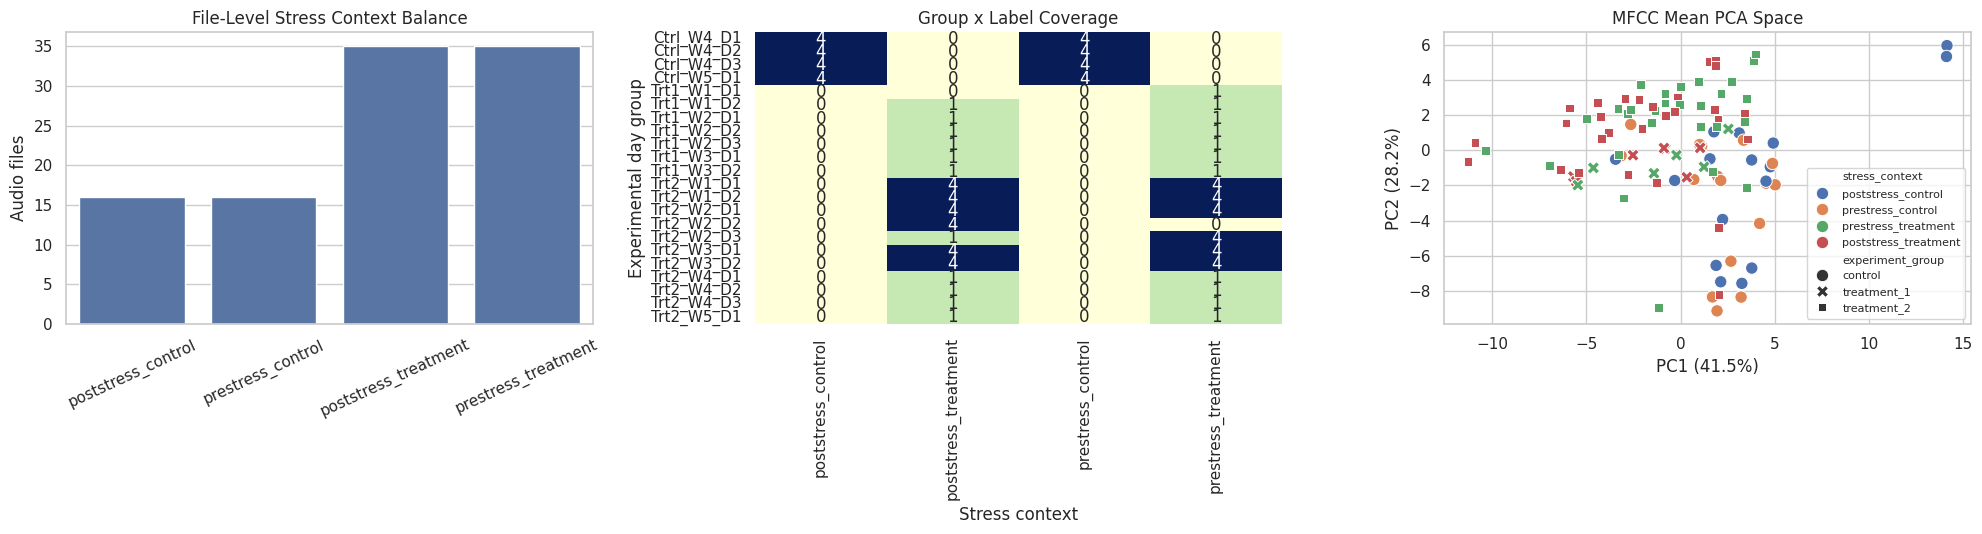

saved: /content/openfarm_laying_hen_stress/prepared/laying_hen_visual_audit.png
{
  "generated_at": "2026-05-17T13:10:39.982473+00:00",
  "source_url": "https://zenodo.org/records/10433023",
  "doi": "10.5281/zenodo.10433023",
  "license": "cc-by-4.0",
  "source_title": "Vocalization Patterns in Laying Hens - An Analysis of Stress-Induced Audio Responses",
  "files": [
    {
      "filename": "Laying Hens Vocalization Control Experiments Data.zip",
      "size": 482016017,
      "expected_checksum": "md5:e5cb4fb7fd21ee6afe9bbcf725476e99"
    },
    {
      "filename": "Laying Hens Vocalization Treatment Experiments Data.zip",
      "size": 1999549757,
      "expected_checksum": "md5:3ea021e99b16e25ed0240cd7688386d5"
    },
    {
      "filename": "Laying Hens Vocalization Data Analysis Dec 26 2023.zip",
      "size": 12690105,
      "expected_checksum": "md5:3e53c8a28eba3510705f5389608771c1"
    }
  ],
  "rows": 102,
  "mfcc_segments": 1213,
  "stress_context_counts": {
    "poststress

In [7]:
#@title Compact audit: distributions and MFCC PCA
sns.set_theme(style="whitegrid")

mfcc_mean_cols = [c for c in metadata_df.columns if c.startswith("mfcc_") and c.endswith("_mean")]
X = metadata_df[mfcc_mean_cols].fillna(metadata_df[mfcc_mean_cols].median())
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X_scaled)
metadata_df["pca1"] = coords[:, 0]
metadata_df["pca2"] = coords[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

sns.countplot(data=metadata_df, x="stress_context", order=STRESS_CONTEXT_CHOICES, ax=axes[0])
axes[0].set_title("File-Level Stress Context Balance")
axes[0].set_xlabel("")
axes[0].set_ylabel("Audio files")
axes[0].tick_params(axis="x", rotation=25)

heat = pd.crosstab(metadata_df["experimental_day_group"], metadata_df["stress_context"])
sns.heatmap(heat, cmap="YlGnBu", annot=True, fmt="g", cbar=False, ax=axes[1])
axes[1].set_title("Group x Label Coverage")
axes[1].set_xlabel("Stress context")
axes[1].set_ylabel("Experimental day group")

sns.scatterplot(data=metadata_df, x="pca1", y="pca2", hue="stress_context", style="experiment_group", s=80, ax=axes[2])
axes[2].set_title("MFCC Mean PCA Space")
axes[2].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[2].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[2].legend(fontsize=8)

plt.tight_layout()
fig_path = OUT_DIR / "laying_hen_visual_audit.png"
plt.savefig(fig_path, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", fig_path)

source_manifest = {
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "source_url": ZENODO_RECORD_URL,
    "doi": record["metadata"].get("doi"),
    "license": "cc-by-4.0",
    "source_title": record["metadata"].get("title"),
    "files": [{"filename": f["key"], "size": f["size"], "expected_checksum": f.get("checksum")} for f in record["files"]],
    "rows": int(len(metadata_df)),
    "mfcc_segments": int(len(segment_df)),
    "stress_context_counts": dict(Counter(metadata_df["stress_context"])),
    "stress_binary_counts": dict(Counter(metadata_df["stress_binary"])),
    "experimental_day_groups": int(metadata_df["experimental_day_group"].nunique()),
    "audio_available": dict(Counter(metadata_df["audio_available"])),
    "leakage_policy": "Source filenames encode labels and are kept only in local private mapping artifacts.",
}
manifest_path = OUT_DIR / "source_manifest.json"
manifest_path.write_text(json.dumps(source_manifest, indent=2), encoding="utf-8")
print(json.dumps(source_manifest, indent=2))


In [8]:
#@title Build experimental-day-heldout split and balanced views
labels = metadata_df["stress_context"].tolist()
groups = metadata_df["experimental_day_group"].tolist()
base_counts = Counter(labels)
base_rate = {k: v / len(labels) for k, v in base_counts.items()}

best = None
for seed in range(SEED, SEED + SPLIT_SEED_SEARCH):
    splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE_FALLBACK, random_state=seed)
    train_idx, test_idx = next(splitter.split(metadata_df, labels, groups))
    train_part = metadata_df.iloc[train_idx]
    test_part = metadata_df.iloc[test_idx]
    assert set(train_part["experimental_day_group"]).isdisjoint(set(test_part["experimental_day_group"]))
    test_counts = Counter(test_part["stress_context"])
    if len(test_counts) < len(base_counts):
        continue
    test_rate = {k: test_counts.get(k, 0) / len(test_part) for k in base_counts}
    score = sum(abs(test_rate[k] - base_rate[k]) for k in base_counts)
    score += abs(len(test_part) / len(metadata_df) - TEST_SIZE_FALLBACK)
    candidate = (score, seed, train_part.index.tolist(), test_part.index.tolist())
    if best is None or candidate < best:
        best = candidate

assert best is not None, "No valid split covering all labels was found. Increase SPLIT_SEED_SEARCH."
score, split_seed, train_indices, test_indices = best
train_raw_df = metadata_df.loc[train_indices].copy()
test_raw_df = metadata_df.loc[test_indices].copy()
train_raw_df["split"] = "train_raw"
test_raw_df["split"] = "test_raw"
split_df = pd.concat([train_raw_df, test_raw_df], ignore_index=True)


def make_balanced_view(frame: pd.DataFrame, split_name: str, seed: int) -> pd.DataFrame:
    counts = frame["stress_context"].value_counts()
    n = int(counts.min())
    pieces = []
    for label in STRESS_CONTEXT_CHOICES:
        pieces.append(frame[frame["stress_context"] == label].sample(n=n, random_state=seed))
    out = pd.concat(pieces).sample(frac=1, random_state=seed).reset_index(drop=True)
    out["split"] = split_name
    return out

train_df = make_balanced_view(train_raw_df, "train", split_seed)
test_df = make_balanced_view(test_raw_df, "test", split_seed)

print("split seed:", split_seed, "score:", round(score, 4))
print("train_raw rows/groups:", len(train_raw_df), train_raw_df["experimental_day_group"].nunique())
print("test_raw rows/groups:", len(test_raw_df), test_raw_df["experimental_day_group"].nunique())
print("group overlap:", set(train_raw_df["experimental_day_group"]) & set(test_raw_df["experimental_day_group"]))
print("train_raw labels:", Counter(train_raw_df["stress_context"]))
print("test_raw labels:", Counter(test_raw_df["stress_context"]))
print("train labels:", Counter(train_df["stress_context"]))
print("test labels:", Counter(test_df["stress_context"]))
print("test groups:", sorted(test_raw_df["experimental_day_group"].unique()))

split_df.to_csv(OUT_DIR / "laying_hen_split_raw_metadata.csv", index=False)
train_raw_df.to_csv(OUT_DIR / "laying_hen_train_raw_metadata.csv", index=False)
test_raw_df.to_csv(OUT_DIR / "laying_hen_test_raw_metadata.csv", index=False)
train_df.to_csv(OUT_DIR / "laying_hen_train_metadata.csv", index=False)
test_df.to_csv(OUT_DIR / "laying_hen_test_metadata.csv", index=False)


split seed: 48 score: 0.0539
train_raw rows/groups: 78 16
test_raw rows/groups: 24 6
group overlap: set()
train_raw labels: Counter({'prestress_treatment': 27, 'poststress_treatment': 27, 'poststress_control': 12, 'prestress_control': 12})
test_raw labels: Counter({'poststress_treatment': 8, 'prestress_treatment': 8, 'poststress_control': 4, 'prestress_control': 4})
train labels: Counter({'prestress_treatment': 12, 'poststress_control': 12, 'prestress_control': 12, 'poststress_treatment': 12})
test labels: Counter({'prestress_control': 4, 'prestress_treatment': 4, 'poststress_treatment': 4, 'poststress_control': 4})
test groups: ['Ctrl_W4_D2', 'Trt1_W1_D2', 'Trt1_W2_D2', 'Trt1_W2_D3', 'Trt1_W3_D1', 'Trt2_W2_D1']


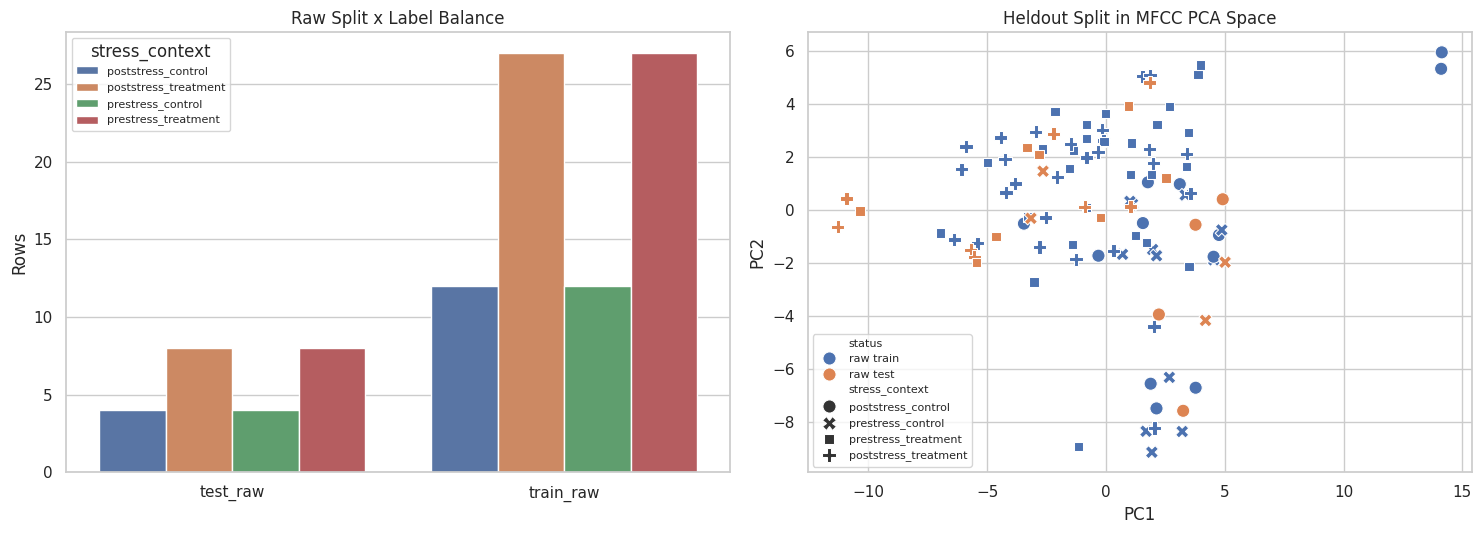

saved: /content/openfarm_laying_hen_stress/prepared/laying_hen_split_audit.png


In [9]:
#@title Split visual audit
plot_df = split_df.copy()
plot_df["status"] = plot_df["split"].map({"train_raw": "raw train", "test_raw": "raw test"})

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
split_counts = plot_df.groupby(["split", "stress_context"]).size().reset_index(name="count")
sns.barplot(data=split_counts, x="split", y="count", hue="stress_context", ax=axes[0])
axes[0].set_title("Raw Split x Label Balance")
axes[0].set_xlabel("")
axes[0].set_ylabel("Rows")
axes[0].legend(title="stress_context", fontsize=8)

sns.scatterplot(data=plot_df, x="pca1", y="pca2", hue="status", style="stress_context", s=90, ax=axes[1])
axes[1].set_title("Heldout Split in MFCC PCA Space")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend(fontsize=8)

plt.tight_layout()
fig_path = OUT_DIR / "laying_hen_split_audit.png"
plt.savefig(fig_path, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", fig_path)


In [10]:
#@title Shallow MFCC baseline check
LABELS_ORDER = STRESS_CONTEXT_CHOICES
MFCC_FEATURES = [c for c in metadata_df.columns if c.startswith("mfcc_") and c.endswith("_mean")]


def run_mfcc_baseline(train_frame: pd.DataFrame, test_frame: pd.DataFrame, name: str) -> dict:
    X_train = train_frame[MFCC_FEATURES].fillna(train_frame[MFCC_FEATURES].median())
    X_test = test_frame[MFCC_FEATURES].fillna(train_frame[MFCC_FEATURES].median())
    y_train = train_frame["stress_context"].tolist()
    y_test = test_frame["stress_context"].tolist()

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    majority = DummyClassifier(strategy="most_frequent")
    majority.fit(X_train_scaled, y_train)
    majority_pred = majority.predict(X_test_scaled)

    clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
    clf.fit(X_train_scaled, y_train)
    pred = clf.predict(X_test_scaled)

    print("\n" + "=" * 80)
    print(name)
    print("test label counts:", Counter(y_test))
    print("Majority baseline")
    print("accuracy:", round(accuracy_score(y_test, majority_pred), 4))
    print("balanced_accuracy:", round(balanced_accuracy_score(y_test, majority_pred), 4))

    print("\nMFCC logistic regression baseline")
    print("accuracy:", round(accuracy_score(y_test, pred), 4))
    print("balanced_accuracy:", round(balanced_accuracy_score(y_test, pred), 4))
    print("macro_f1:", round(f1_score(y_test, pred, labels=LABELS_ORDER, average="macro"), 4))
    print(classification_report(y_test, pred, labels=LABELS_ORDER, digits=3, zero_division=0))
    print("confusion_matrix labels", LABELS_ORDER)
    print(confusion_matrix(y_test, pred, labels=LABELS_ORDER))

    return {
        "name": name,
        "train_rows": len(train_frame),
        "test_rows": len(test_frame),
        "test_label_counts": dict(Counter(y_test)),
        "majority_accuracy": accuracy_score(y_test, majority_pred),
        "majority_balanced_accuracy": balanced_accuracy_score(y_test, majority_pred),
        "mfcc_accuracy": accuracy_score(y_test, pred),
        "mfcc_balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "mfcc_macro_f1": f1_score(y_test, pred, labels=LABELS_ORDER, average="macro"),
        "mfcc_confusion_matrix": confusion_matrix(y_test, pred, labels=LABELS_ORDER).tolist(),
    }

baseline_audit = {
    "balanced_split": run_mfcc_baseline(train_df, test_df, "Balanced published split: train/test"),
    "raw_split": run_mfcc_baseline(train_raw_df, test_raw_df, "Natural distribution split: train_raw/test_raw"),
}

with (OUT_DIR / "baseline_audit.json").open("w") as f:
    json.dump(baseline_audit, f, indent=2, ensure_ascii=False)
print("saved:", OUT_DIR / "baseline_audit.json")



Balanced published split: train/test
test label counts: Counter({'prestress_control': 4, 'prestress_treatment': 4, 'poststress_treatment': 4, 'poststress_control': 4})
Majority baseline
accuracy: 0.25
balanced_accuracy: 0.25

MFCC logistic regression baseline
accuracy: 0.25
balanced_accuracy: 0.25
macro_f1: 0.2222
                      precision    recall  f1-score   support

  poststress_control      0.600     0.750     0.667         4
   prestress_control      0.200     0.250     0.222         4
poststress_treatment      0.000     0.000     0.000         4
 prestress_treatment      0.000     0.000     0.000         4

            accuracy                          0.250        16
           macro avg      0.200     0.250     0.222        16
        weighted avg      0.200     0.250     0.222        16

confusion_matrix labels ['poststress_control', 'prestress_control', 'poststress_treatment', 'prestress_treatment']
[[3 1 0 0]
 [0 1 2 1]
 [2 2 0 0]
 [0 1 3 0]]

Natural distribution sp

In [11]:
#@title Validate leakage guards and consolidate public dataset rows
split_frames = {"train": train_df, "test": test_df, "train_raw": train_raw_df, "test_raw": test_raw_df}

# Keep meaningful experimental metadata. Drop only private/source filename provenance.
PUBLIC_FORBIDDEN_COLUMNS = {"source_audio_filename", "source_archive", "source_archive_member", "source_audio_sha256"}
PUBLIC_COLUMNS = [
    "source_audio_id", "source_group_id", "species", "arm_code", "experiment_group", "stressor",
    "week", "day", "phase", "clip_index", "experimental_day_group", "mfcc_segment_count",
    "stress_context", "stress_binary", "audio_filename", "audio_sha256", "duration_sec",
    "sample_rate_hz", "channels", "source_duration_sec", "source_sample_rate_hz", "source_channels",
    "excerpt_duration_sec", "excerpt_max_seconds", "excerpt_strategy", "excerpt_window_count",
    "excerpt_sample_rate_hz", "excerpt_windows_sec", "audio_metadata_ok", "audio_metadata_backend",
]

consolidated_rows = []
for split_name, frame in split_frames.items():
    for _, row in frame.iterrows():
        assert row["stress_context"] in STRESS_CONTEXT_CHOICES
        assert row["audio_filename"].startswith("hen_")
        assert row["source_group_id"].startswith("hen_group_")
        assert not any(token in row["audio_filename"] for token in ["Ctrl", "Trt", "PoS", "PrS"])
        public_row = {col: row.get(col, "") for col in PUBLIC_COLUMNS}
        if bool(row.get("audio_available", False)) and not bool(row.get("audio_metadata_ok", False)):
            raise RuntimeError(f"Audio file is present but metadata inspection failed: {row.get('audio_filename')} {row.get('audio_metadata_error', '')}")
        if bool(row.get("audio_available", False)):
            if float(row["duration_sec"]) > AUDIO_EXCERPT_MAX_SECONDS + 0.05:
                raise RuntimeError(f"Prepared audio exceeds excerpt ceiling: {row['audio_filename']} duration={row['duration_sec']}")
            public_row["audio"] = row["audio"]
        public_row["source_url"] = ZENODO_RECORD_URL
        public_row["source_doi"] = record["metadata"].get("doi") or ""
        public_row["license"] = "cc-by-4.0"
        public_row["split"] = split_name
        consolidated_rows.append(public_row)

hf_df = pd.DataFrame(consolidated_rows)
assert not (PUBLIC_FORBIDDEN_COLUMNS & set(hf_df.columns)), PUBLIC_FORBIDDEN_COLUMNS & set(hf_df.columns)

all_audio_available = "audio" in hf_df.columns and hf_df["audio"].map(lambda p: bool(p) and Path(p).exists()).all()
print("all audio available:", all_audio_available)
if not all_audio_available:
    print("warning: public rows were built without complete audio paths. The push cell will stop if REQUIRE_AUDIO_FOR_PUSH=True.")
else:
    print("public duration max:", float(hf_df["duration_sec"].max()))
    print("public source duration max:", float(hf_df["source_duration_sec"].max()))

hf_path = OUT_DIR / "laying_hen_hf_dataset.jsonl"
hf_df.to_json(hf_path, orient="records", lines=True, force_ascii=False)

print("dataset total rows:", len(hf_df))
print("public columns:", list(hf_df.columns))
print("wrote:", hf_path)
display(hf_df[["audio_filename", "split", "duration_sec", "source_duration_sec", "stress_context", "experiment_group", "stressor", "phase", "experimental_day_group"]].head())


all audio available: True
public duration max: 15.0
public source duration max: 3820.303673469388
dataset total rows: 166
public columns: ['source_audio_id', 'source_group_id', 'species', 'arm_code', 'experiment_group', 'stressor', 'week', 'day', 'phase', 'clip_index', 'experimental_day_group', 'mfcc_segment_count', 'stress_context', 'stress_binary', 'audio_filename', 'audio_sha256', 'duration_sec', 'sample_rate_hz', 'channels', 'source_duration_sec', 'source_sample_rate_hz', 'source_channels', 'excerpt_duration_sec', 'excerpt_max_seconds', 'excerpt_strategy', 'excerpt_window_count', 'excerpt_sample_rate_hz', 'excerpt_windows_sec', 'audio_metadata_ok', 'audio_metadata_backend', 'audio', 'source_url', 'source_doi', 'license', 'split']
wrote: /content/openfarm_laying_hen_stress/prepared/laying_hen_hf_dataset.jsonl


,audio_filename,split,duration_sec,source_duration_sec,stress_context,experiment_group,stressor,phase,experimental_day_group
0,hen_4d870fd2cd24.wav,train,15.0,1060.441882,prestress_treatment,treatment_2,simulated_dog_barking,prestress,Trt2_W1_D2
1,hen_c98829d152bb.wav,train,15.0,1060.441882,poststress_control,control,none,poststress,Ctrl_W4_D3
2,hen_df90ae83c4fe.wav,train,15.0,1060.441882,poststress_control,control,none,poststress,Ctrl_W5_D1
3,hen_405ce7549050.wav,train,15.0,612.076168,prestress_control,control,none,prestress,Ctrl_W4_D3
4,hen_03aff296bdbb.wav,train,15.0,3723.807347,prestress_treatment,treatment_2,simulated_dog_barking,prestress,Trt2_W4_D2


In [12]:
#@title Build Hugging Face DatasetDict preview
split_datasets = {}
for split_name in ["train", "test", "train_raw", "test_raw"]:
    frame = hf_df[hf_df["split"] == split_name].drop(columns=["split"]).reset_index(drop=True)
    split_datasets[split_name] = Dataset.from_pandas(frame, preserve_index=False)

ds = DatasetDict(split_datasets)
if "audio" in ds["train"].column_names:
    ds = ds.cast_column("audio", Audio(sampling_rate=AUDIO_EXCERPT_SAMPLE_RATE, decode=False))

print(ds)
preview = ds["train"][0]
if "audio" in preview:
    preview = dict(preview)
    preview["audio"] = {k: preview["audio"].get(k) for k in ["path", "bytes"] if k in preview["audio"]}
print(preview)


DatasetDict({
    train: Dataset({
        features: ['source_audio_id', 'source_group_id', 'species', 'arm_code', 'experiment_group', 'stressor', 'week', 'day', 'phase', 'clip_index', 'experimental_day_group', 'mfcc_segment_count', 'stress_context', 'stress_binary', 'audio_filename', 'audio_sha256', 'duration_sec', 'sample_rate_hz', 'channels', 'source_duration_sec', 'source_sample_rate_hz', 'source_channels', 'excerpt_duration_sec', 'excerpt_max_seconds', 'excerpt_strategy', 'excerpt_window_count', 'excerpt_sample_rate_hz', 'excerpt_windows_sec', 'audio_metadata_ok', 'audio_metadata_backend', 'audio', 'source_url', 'source_doi', 'license'],
        num_rows: 48
    })
    test: Dataset({
        features: ['source_audio_id', 'source_group_id', 'species', 'arm_code', 'experiment_group', 'stressor', 'week', 'day', 'phase', 'clip_index', 'experimental_day_group', 'mfcc_segment_count', 'stress_context', 'stress_binary', 'audio_filename', 'audio_sha256', 'duration_sec', 'sample_rate_hz', 

In [13]:
#@title Dataset card scaffold
train_counts = dict(Counter(train_df["stress_context"]))
test_counts = dict(Counter(test_df["stress_context"]))
train_raw_counts = dict(Counter(train_raw_df["stress_context"]))
test_raw_counts = dict(Counter(test_raw_df["stress_context"]))
all_counts = dict(Counter(metadata_df["stress_context"]))

audio_count = int(metadata_df["audio_available"].sum())
source_duration_summary = "not available"
excerpt_duration_summary = "not available"
if metadata_df["audio_available"].any():
    source_duration_summary = {
        "min": float(metadata_df["source_duration_sec"].min()),
        "median": float(metadata_df["source_duration_sec"].median()),
        "max": float(metadata_df["source_duration_sec"].max()),
    }
    excerpt_duration_summary = {
        "min": float(metadata_df["duration_sec"].min()),
        "median": float(metadata_df["duration_sec"].median()),
        "max": float(metadata_df["duration_sec"].max()),
    }

card = f"""---
license: cc-by-4.0
language:
- en
pretty_name: OpenFARM Laying Hen Stress Vocalizations
size_categories:
- n<1K
tags:
- animal-welfare
- poultry
- laying-hen
- audio
- bioacoustics
- stress
- openfarm
---

# OpenFARM Laying Hen Stress Vocalizations

This prepared dataset derives from the Zenodo record **Vocalization Patterns in Laying Hens - An Analysis of Stress-Induced Audio Responses**.

Source: {ZENODO_RECORD_URL}
DOI: {record['metadata'].get('doi')}
Source title: {record['metadata'].get('title')}
Source license: CC-BY-4.0
Prepared: {datetime.now(timezone.utc).date().isoformat()}

## Scope

This is a laying-hen **audio stress-context classification** dataset. Given a bounded audio excerpt derived from a source recording, predict the source experimental context:

- `poststress_control`
- `prestress_control`
- `poststress_treatment`
- `prestress_treatment`

A derived binary label, `stress_binary`, marks only `poststress_treatment` as `stress_response`. This is useful for stress-proxy evaluation, but it should not be described as a clinical diagnosis.

## Source Processing Summary

- Source MFCC segment rows: {len(segment_df)}
- Source audio files represented in MFCC table: {len(metadata_df)}
- Experimental day groups: {metadata_df['experimental_day_group'].nunique()}
- Source stress-context counts: {all_counts}
- Audio files available in this prepared run: {audio_count}/{len(metadata_df)}
- Source recording duration summary, seconds: {source_duration_summary}
- Public excerpt duration summary, seconds: {excerpt_duration_summary}

## Audio Excerpt Policy

The original Zenodo recordings can be roughly 10-17 minutes long. Public HF audio in this prepared dataset is not the full source recording. Each public audio artifact is a deterministic, opaque **{AUDIO_EXCERPT_MAX_SECONDS:g}s ceiling** excerpt written as {AUDIO_EXCERPT_SAMPLE_RATE} Hz mono {AUDIO_EXCERPT_FORMAT}/{AUDIO_EXCERPT_SUBTYPE}.

The default excerpt strategy is `{AUDIO_EXCERPT_STRATEGY}` with `{AUDIO_EXCERPT_WINDOW_COUNT}` windows. Because the source MFCC table does not provide event timestamps, this samples several positions across the source recording instead of assuming the informative stress-related vocalization is at the beginning or center.

## Data Shape

Each public row represents one source audio recording listed by the MFCC table, paired with one bounded public audio excerpt. DatasetDict split membership is stored by split name, so the `split` column is not included inside each public split.

Main fields:

- `audio`: HF `Audio` feature containing the bounded public excerpt
- `audio_filename`: opaque prepared filename, not the source filename
- `source_audio_id`: opaque stable source-recording ID
- `source_group_id`: opaque grouping ID used for leakage-aware analysis
- `species`: always `laying_hen`
- `arm_code`, `experiment_group`, `stressor`, `week`, `day`, `phase`, `clip_index`, `experimental_day_group`: parsed source experimental metadata for audits and ablations
- `mfcc_segment_count`: number of MFCC segment rows for the source recording
- `stress_context`: four-class target label
- `stress_binary`: binary stress-proxy label; only `poststress_treatment` is marked `stress_response`
- `duration_sec`, `sample_rate_hz`, `channels`, `audio_sha256`, `audio_metadata_ok`, `audio_metadata_backend`: public excerpt metadata and tracking fields
- `source_duration_sec`, `source_sample_rate_hz`, `source_channels`: non-identifying source recording metadata for audit only
- `excerpt_duration_sec`, `excerpt_max_seconds`, `excerpt_strategy`, `excerpt_window_count`, `excerpt_sample_rate_hz`, `excerpt_windows_sec`: public excerpt construction metadata
- `source_url`, `source_doi`, `license`: attribution fields

Original source filenames and source archive members are deliberately excluded from public rows because filenames encode treatment and phase. The notebook writes a local `source_mapping_private.csv` for audit/reproducibility, but it is not included in public HF rows.

For the primary audio benchmark, env prompts should expose audio excerpts or otherwise budgeted audio plus answer options, not parsed metadata such as `phase`, `experiment_group`, `stressor`, `week`, or `day`. Those fields are kept so future envs can run source-aware audits and ablations.

## Splits

Splits are experimental-day-heldout at the raw train/test boundary. No `experimental_day_group` appears in both raw train and raw test.

Prepared splits:

- `train`: class-balanced view sampled from the heldout raw train set; counts {train_counts}
- `test`: class-balanced view sampled from the heldout raw test set; counts {test_counts}
- `train_raw`: natural heldout train distribution; counts {train_raw_counts}
- `test_raw`: natural heldout test distribution; counts {test_raw_counts}

Use `train`/`test` for balanced OpenFARM env development and quick model comparisons. Use `train_raw`/`test_raw` when reporting behavior on the source distribution.

## Metrics

Recommended metrics: accuracy, balanced accuracy, macro F1, per-class precision/recall/F1, confusion matrix, majority-class baseline, and shallow MFCC-feature baseline from `baseline_audit.json`.

## Limitations

The dataset is small and experimental metadata is strongly structured. Source recordings can be long and are not single isolated calls. The bounded public excerpts are deterministic benchmark artifacts, not expert-localized event windows. This dataset is best used as a compact poultry audio stress-context probe, not as a broad poultry welfare diagnosis benchmark or clinical stress diagnosis dataset. Subject IDs for individual hens are not available, so the split holds out experimental day groups rather than animals.
"""

card_path = OUT_DIR / "README.md"
card_path.write_text(card, encoding="utf-8")
print(card)


---
license: cc-by-4.0
language:
- en
pretty_name: OpenFARM Laying Hen Stress Vocalizations
size_categories:
- n<1K
tags:
- animal-welfare
- poultry
- laying-hen
- audio
- bioacoustics
- stress
- openfarm
---

# OpenFARM Laying Hen Stress Vocalizations

This prepared dataset derives from the Zenodo record **Vocalization Patterns in Laying Hens - An Analysis of Stress-Induced Audio Responses**.

Source: https://zenodo.org/records/10433023
DOI: 10.5281/zenodo.10433023
Source title: Vocalization Patterns in Laying Hens - An Analysis of Stress-Induced Audio Responses
Source license: CC-BY-4.0
Prepared: 2026-05-17

## Scope

This is a laying-hen **audio stress-context classification** dataset. Given a bounded audio excerpt derived from a source recording, predict the source experimental context:

- `poststress_control`
- `prestress_control`
- `poststress_treatment`
- `prestress_treatment`

A derived binary label, `stress_binary`, marks only `poststress_treatment` as `stress_response`. This 

In [15]:
#@title Optional push to Hugging Face Hub
# Keep PUSH_TO_HUB=False while iterating. This cell does not print tokens.

if PUSH_TO_HUB:
    if REQUIRE_AUDIO_FOR_PUSH:
        if "audio" not in ds["train"].column_names:
            raise RuntimeError("Audio column missing. Rerun audio extraction and inspect `audio availability` before pushing.")
        missing_audio = []
        for split_name, split_ds in ds.items():
            for i, row in enumerate(split_ds):
                audio = row.get("audio")
                path = audio.get("path") if isinstance(audio, dict) else None
                if not path or not Path(path).exists():
                    missing_audio.append((split_name, i, row.get("audio_filename")))
                    break
        if missing_audio:
            raise RuntimeError(f"Some audio files are missing; first failures: {missing_audio[:5]}")

    token = os.environ.get("HF_TOKEN")
    if token is None:
        try:
            from google.colab import userdata
            token = userdata.get("HF_TOKEN")
        except Exception:
            token = None
    if token:
        login(token=token, add_to_git_credential=False)
    else:
        print("No HF_TOKEN found. You can run huggingface-cli login or set HF_TOKEN, then rerun this cell.")

    api = HfApi()
    api.create_repo(repo_id=HF_REPO_ID, repo_type="dataset", private=PRIVATE_REPO, exist_ok=True)
    ds.push_to_hub(HF_REPO_ID, private=PRIVATE_REPO)
    api.upload_file(
        path_or_fileobj=str(OUT_DIR / "README.md"),
        path_in_repo="README.md",
        repo_id=HF_REPO_ID,
        repo_type="dataset",
    )
    print("pushed:", f"https://huggingface.co/datasets/{HF_REPO_ID}")
else:
    print("dry run only. Set PUSH_TO_HUB=True after reviewing outputs.")


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/48 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  95%|#########5| 8.36MB / 8.79MB            

README.md: 0.00B [00:00, ?B/s]

pushed: https://huggingface.co/datasets/oliveirabruno01/openfarm-laying-hen-stress


# Review checklist

Before publishing or building a Verifiers env:

- verify Zenodo MD5s for all downloaded archives
- confirm source license is CC-BY-4.0 and citation fields are preserved
- confirm original source filenames and archive members are absent from public HF rows
- confirm `source_mapping_private.csv` stays local/private
- confirm every pushed public row has an `audio` feature when building an audio env
- confirm no `experimental_day_group` overlap between raw train/test
- report balanced accuracy and macro F1, not plain accuracy alone
- inspect several audio/label pairs manually
